In [ ]:








import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 2019-Oct-sample.csv to 2019-Oct-sample.csv


In [ ]:
df = pd.read_csv("2019-Oct-sample.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (500000, 9)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

Rows: 500000
Columns: 9

Columns:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     500000 non-null  object 
 1   event_type     500000 non-null  object 
 2   product_id     500000 non-null  int64  
 3   category_id    500000 non-null  int64  
 4   category_code  341561 non-null  object 
 5   brand          428149 non-null  object 
 6   price          500000 non-null  float64
 7   user_id        500000 non-null  int64  
 8   user_session   500000 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 34.3+ MB


In [ ]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
event_time            0
event_type            0
product_id            0
category_id           0
category_code    158439
brand             71851
price                 0
user_id               0
user_session          0
dtype: int64


In [ ]:
print("Event types:")
print(df["event_type"].value_counts())

Event types:
event_type
view        481833
purchase      9758
cart          8409
Name: count, dtype: int64


In [ ]:
df.describe(include="all")

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
count,500000,500000,5.000000e+05,5.000000e+05,341561,428149,500000.000000,5.000000e+05,500000
unique,29995,3,NaN,NaN,123,2028,NaN,NaN,117455
top,2019-10-01 08:42:43 UTC,view,NaN,NaN,electronics.smartphone,samsung,NaN,NaN,0aba42f1-a8d1-4171-80dd-5b0b514972e3
freq,75,481833,NaN,NaN,137997,60975,NaN,NaN,147
mean,NaN,NaN,1.010429e+07,2.056139e+18,NaN,NaN,293.302819,5.311002e+08,NaN
std,NaN,NaN,1.103979e+07,1.525755e+16,NaN,NaN,365.723828,1.657961e+07,NaN
min,NaN,NaN,1.001588e+06,2.053014e+18,NaN,NaN,0.000000,2.449511e+08,NaN
25%,NaN,NaN,1.005115e+06,2.053014e+18,NaN,NaN,63.195000,5.156270e+08,NaN
50%,NaN,NaN,5.100281e+06,2.053014e+18,NaN,NaN,157.790000,5.267932e+08,NaN
75%,NaN,NaN,1.580005e+07,2.053014e+18,NaN,NaN,360.110000,5.477962e+08,NaN


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 288


In [ ]:
print("Unique users:", df["user_id"].nunique())
print("Unique sessions:", df["user_session"].nunique())
print("Unique products:", df["product_id"].nunique())

Unique users: 89124
Unique sessions: 117455
Unique products: 46897


In [ ]:
# Create a copy of the original dataset
clean_df = df.copy()

# 1. Remove exact duplicate records
clean_df = clean_df.drop_duplicates()

# 2. Convert event_time to datetime
clean_df["event_time"] = pd.to_datetime(
    clean_df["event_time"],
    errors="coerce"
)

# 3. Check valid event types
valid_events = ["view", "cart", "purchase"]

invalid_events = ~clean_df["event_type"].isin(valid_events)

print("Invalid event records:", invalid_events.sum())

# 4. Check missing essential fields
print("Missing user IDs:", clean_df["user_id"].isna().sum())
print("Missing session IDs:", clean_df["user_session"].isna().sum())

# 5. Check invalid prices
print(
    "Invalid prices:",
    ((clean_df["price"] < 0) | (clean_df["price"].isna())).sum()
)

# 6. Sort events chronologically within each session
clean_df = clean_df.sort_values(
    ["user_session", "event_time"]
).reset_index(drop=True)

print("\nOriginal rows:", len(df))
print("Cleaned rows:", len(clean_df))

Invalid event records: 0
Missing user IDs: 0
Missing session IDs: 0
Invalid prices: 0

Original rows: 500000
Cleaned rows: 499712


In [ ]:
# Define funnel stages
funnel_events = ["view", "cart", "purchase"]

# Calculate unique users at each funnel stage
funnel_users = {}

for event in funnel_events:
    funnel_users[event] = clean_df.loc[
        clean_df["event_type"] == event,
        "user_id"
    ].nunique()

print("Unique users at each funnel stage:")
for event, count in funnel_users.items():
    print(f"{event.capitalize()}: {count:,}")

Unique users at each funnel stage:
View: 89,108
Cart: 4,441
Purchase: 7,362


In [ ]:
view_users = funnel_users["view"]
cart_users = funnel_users["cart"]
purchase_users = funnel_users["purchase"]

view_to_cart = (cart_users / view_users) * 100
cart_to_purchase = (purchase_users / cart_users) * 100
view_to_purchase = (purchase_users / view_users) * 100

view_cart_dropoff = 100 - view_to_cart
cart_purchase_dropoff = 100 - cart_to_purchase

print(f"View → Cart conversion: {view_to_cart:.2f}%")
print(f"Cart → Purchase conversion: {cart_to_purchase:.2f}%")
print(f"View → Purchase conversion: {view_to_purchase:.2f}%")

print(f"\nView → Cart drop-off: {view_cart_dropoff:.2f}%")
print(f"Cart → Purchase drop-off: {cart_purchase_dropoff:.2f}%")

View → Cart conversion: 4.98%
Cart → Purchase conversion: 165.77%
View → Purchase conversion: 8.26%

View → Cart drop-off: 95.02%
Cart → Purchase drop-off: -65.77%


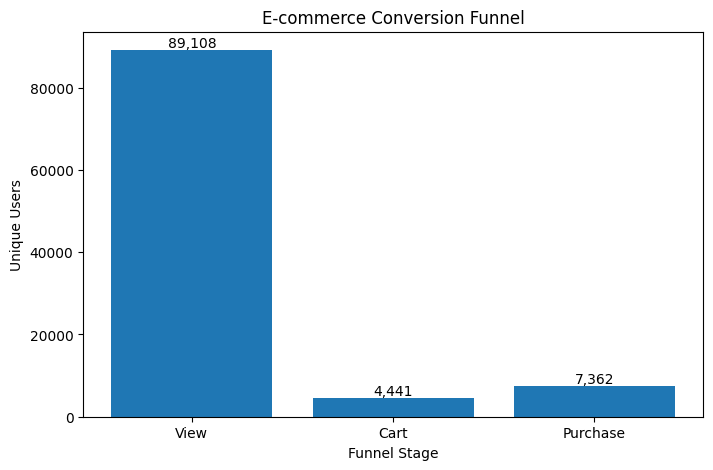

In [ ]:
# Funnel data
stages = ["View", "Cart", "Purchase"]
users = [view_users, cart_users, purchase_users]

plt.figure(figsize=(8, 5))
plt.bar(stages, users)

plt.title("E-commerce Conversion Funnel")
plt.xlabel("Funnel Stage")
plt.ylabel("Unique Users")

for i, value in enumerate(users):
    plt.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.show()

In [ ]:
funnel_results = pd.DataFrame({
    "Stage": ["View", "Cart", "Purchase"],
    "Unique Users": [view_users, cart_users, purchase_users]
})

funnel_results["Conversion from Previous Stage (%)"] = [
    100,
    view_to_cart,
    cart_to_purchase
]

funnel_results["Drop-off from Previous Stage (%)"] = [
    0,
    view_cart_dropoff,
    cart_purchase_dropoff
]

funnel_results

,Stage,Unique Users,Conversion from Previous Stage (%),Drop-off from Previous Stage (%)
0,View,89108,100.000000,0.000000
1,Cart,4441,4.983840,95.016160
2,Purchase,7362,165.773474,-65.773474


### 8. Sequence-Aware Funnel Analysis

To quantify actual funnel progression, events are evaluated chronologically within each user session. A session is considered to reach a funnel stage only when the corresponding event occurs after the preceding stage.

In [ ]:
# Ensure events are ordered chronologically
session_df = clean_df.sort_values(
    ["user_session", "event_time"]
).copy()

# Track whether each session reached each funnel stage
def check_funnel(session):
    events = session["event_type"].tolist()

    view_pos = None
    cart_pos = None
    purchase_pos = None

    # Find first view
    if "view" in events:
        view_pos = events.index("view")

    # Find first cart after view
    if view_pos is not None:
        for i in range(view_pos + 1, len(events)):
            if events[i] == "cart":
                cart_pos = i
                break

    # Find first purchase after cart
    if cart_pos is not None:
        for i in range(cart_pos + 1, len(events)):
            if events[i] == "purchase":
                purchase_pos = i
                break

    return pd.Series({
        "view_reached": view_pos is not None,
        "cart_reached": cart_pos is not None,
        "purchase_reached": purchase_pos is not None
    })

session_funnel = session_df.groupby(
    "user_session",
    group_keys=False
).apply(check_funnel)

session_funnel.head()

/tmp/ipykernel_828/3233435932.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(check_funnel)


,view_reached,cart_reached,purchase_reached
user_session,,,
00016bb9-b50d-4bcb-95d1-9c375f214c66,True,False,False
0001d713-f9c4-4d96-8f8c-5da2bff7bbf9,True,False,False
0002c5ea-3509-4d0b-9618-7e40925005f0,True,False,False
000452e3-cfba-4c6f-93e4-5231fb80a248,True,False,False
0004877e-8ef5-4ffd-90bf-d293b9973991,True,False,False


In [ ]:
# Count sessions reaching each sequential stage
view_sessions = session_funnel["view_reached"].sum()
cart_sessions = (
    session_funnel["view_reached"] &
    session_funnel["cart_reached"]
).sum()

purchase_sessions = (
    session_funnel["view_reached"] &
    session_funnel["cart_reached"] &
    session_funnel["purchase_reached"]
).sum()

print("Sequence-aware funnel:")
print(f"View sessions: {view_sessions:,}")
print(f"View → Cart sessions: {cart_sessions:,}")
print(f"View → Cart → Purchase sessions: {purchase_sessions:,}")

Sequence-aware funnel:
View sessions: 117,406
View → Cart sessions: 5,057
View → Cart → Purchase sessions: 2,858


In [ ]:
# Sequential conversion rates
view_to_cart_seq = (cart_sessions / view_sessions) * 100
cart_to_purchase_seq = (purchase_sessions / cart_sessions) * 100
view_to_purchase_seq = (purchase_sessions / view_sessions) * 100

# Sequential drop-offs
view_cart_dropoff_seq = 100 - view_to_cart_seq
cart_purchase_dropoff_seq = 100 - cart_to_purchase_seq

print(f"View → Cart conversion: {view_to_cart_seq:.2f}%")
print(f"Cart → Purchase conversion: {cart_to_purchase_seq:.2f}%")
print(f"Overall View → Purchase conversion: {view_to_purchase_seq:.2f}%")

print(f"\nView → Cart drop-off: {view_cart_dropoff_seq:.2f}%")
print(f"Cart → Purchase drop-off: {cart_purchase_dropoff_seq:.2f}%")

View → Cart conversion: 4.31%
Cart → Purchase conversion: 56.52%
Overall View → Purchase conversion: 2.43%

View → Cart drop-off: 95.69%
Cart → Purchase drop-off: 43.48%


### 9. O1 — Funnel Results and Drop-off Quantification

The sequence-aware funnel evaluates events chronologically within the same user session. A session progresses from View to Cart only when a cart event occurs after a view, and progresses to Purchase only when a purchase occurs after the cart event.

In [ ]:
# Final sequence-aware funnel results table

sequence_funnel_results = pd.DataFrame({
    "Stage": [
        "View",
        "View → Cart",
        "View → Cart → Purchase"
    ],
    "Sessions": [
        view_sessions,
        cart_sessions,
        purchase_sessions
    ],
    "Conversion (%)": [
        100,
        view_to_cart_seq,
        view_to_purchase_seq
    ],
    "Drop-off (%)": [
        0,
        view_cart_dropoff_seq,
        100 - view_to_purchase_seq
    ]
})

sequence_funnel_results

,Stage,Sessions,Conversion (%),Drop-off (%)
0,View,117406,100.000000,0.000000
1,View → Cart,5057,4.307276,95.692724
2,View → Cart → Purchase,2858,2.434288,97.565712


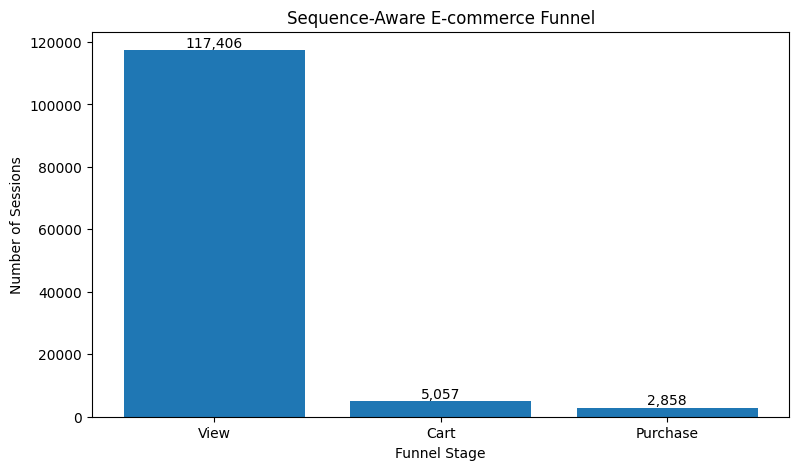

In [ ]:
plt.figure(figsize=(9, 5))

stages = ["View", "Cart", "Purchase"]
values = [view_sessions, cart_sessions, purchase_sessions]

bars = plt.bar(stages, values)

plt.title("Sequence-Aware E-commerce Funnel")
plt.xlabel("Funnel Stage")
plt.ylabel("Number of Sessions")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.show()

### 10. O1 — Data Quality Validation

In [ ]:
# O1 Data Quality Validation

quality_report = {
    "Total records": len(clean_df),
    "Duplicate records": clean_df.duplicated().sum(),
    "Missing user IDs": clean_df["user_id"].isna().sum(),
    "Missing session IDs": clean_df["user_session"].isna().sum(),
    "Missing event times": clean_df["event_time"].isna().sum(),
    "Invalid event types": (~clean_df["event_type"].isin(
        ["view", "cart", "purchase"]
    )).sum(),
    "Invalid prices": (
        (clean_df["price"] < 0) |
        (clean_df["price"].isna())
    ).sum()
}

quality_report_df = pd.DataFrame(
    list(quality_report.items()),
    columns=["Quality Check", "Result"]
)

quality_report_df

,Quality Check,Result
0,Total records,499712
1,Duplicate records,0
2,Missing user IDs,0
3,Missing session IDs,0
4,Missing event times,0
5,Invalid event types,0
6,Invalid prices,0


### 11. O1 — Session and Time Consistency Validation

In [ ]:
# Check whether a session is associated with multiple users
session_user_counts = clean_df.groupby("user_session")["user_id"].nunique()

multi_user_sessions = (session_user_counts > 1).sum()

# Check chronological ordering within each session
time_order_check = (
    clean_df.groupby("user_session")["event_time"]
    .apply(lambda x: x.is_monotonic_increasing)
)

unordered_sessions = (~time_order_check).sum()

print("Sessions associated with multiple users:", multi_user_sessions)
print("Sessions with non-chronological events:", unordered_sessions)

Sessions associated with multiple users: 4
Sessions with non-chronological events: 0


In [ ]:
# Identify sessions associated with multiple users
problem_sessions = session_user_counts[
    session_user_counts > 1
].index

print("Problematic sessions:")
print(problem_sessions.tolist())

Problematic sessions:
['2759bd71-1333-4348-816d-c02912f6ebd4', '42a39e3a-1ed6-40db-be9c-b21182f3dbc3', 'e5fa54c1-935b-41e1-bb95-06fd18cad496', 'fa8092eb-7df8-4bcd-866a-3b2b8eeafea5']


In [ ]:
problem_data = clean_df[
    clean_df["user_session"].isin(problem_sessions)
].sort_values(["user_session", "event_time"])

problem_data[
    ["event_time", "event_type", "user_id",
     "user_session", "product_id", "price"]
]

,event_time,event_type,user_id,user_session,product_id,price
76921,2019-10-01 02:27:45+00:00,view,555463297,2759bd71-1333-4348-816d-c02912f6ebd4,10300637,14.39
76922,2019-10-01 02:28:27+00:00,view,555463292,2759bd71-1333-4348-816d-c02912f6ebd4,10301026,11.56
129469,2019-10-01 09:39:11+00:00,view,555570137,42a39e3a-1ed6-40db-be9c-b21182f3dbc3,1004249,738.39
129470,2019-10-01 09:39:21+00:00,view,555570137,42a39e3a-1ed6-40db-be9c-b21182f3dbc3,1004258,733.81
129471,2019-10-01 09:39:49+00:00,view,555570137,42a39e3a-1ed6-40db-be9c-b21182f3dbc3,1004251,1052.54
129472,2019-10-01 09:42:12+00:00,view,522543493,42a39e3a-1ed6-40db-be9c-b21182f3dbc3,1004741,185.70
449402,2019-10-01 05:26:28+00:00,view,555496461,e5fa54c1-935b-41e1-bb95-06fd18cad496,4100138,413.91
449403,2019-10-01 05:37:04+00:00,view,523810456,e5fa54c1-935b-41e1-bb95-06fd18cad496,4100346,391.00
489237,2019-10-01 09:24:58+00:00,view,555565912,fa8092eb-7df8-4bcd-866a-3b2b8eeafea5,1002629,377.09
489238,2019-10-01 09:25:20+00:00,view,555565910,fa8092eb-7df8-4bcd-866a-3b2b8eeafea5,1002628,397.95


In [ ]:
# Measure the impact of anomalous sessions

problem_rows = clean_df[
    clean_df["user_session"].isin(problem_sessions)
]

print("Anomalous sessions:", len(problem_sessions))
print("Rows affected:", len(problem_rows))
print("Percentage of cleaned data affected:",
      f"{len(problem_rows) / len(clean_df) * 100:.4f}%")

Anomalous sessions: 4
Rows affected: 13
Percentage of cleaned data affected: 0.0026%


In [ ]:
# Exclude sessions associated with multiple users
validated_df = clean_df[
    ~clean_df["user_session"].isin(problem_sessions)
].copy()

print("Original cleaned records:", len(clean_df))
print("Validated records:", len(validated_df))
print("Removed anomalous records:", len(clean_df) - len(validated_df))

Original cleaned records: 499712
Validated records: 499699
Removed anomalous records: 13


In [ ]:
validated_session_users = (
    validated_df.groupby("user_session")["user_id"]
    .nunique()
)

print(
    "Sessions still associated with multiple users:",
    (validated_session_users > 1).sum()
)

Sessions still associated with multiple users: 0


### 12. O1 — Final Validated Funnel Analysis

In [ ]:
# Sort validated data chronologically
validated_df = validated_df.sort_values(
    ["user_session", "event_time"]
).copy()

# Rebuild sequence-aware funnel
def check_funnel_validated(session):
    events = session["event_type"].tolist()

    try:
        view_pos = events.index("view")
    except ValueError:
        return pd.Series({
            "view_reached": False,
            "cart_reached": False,
            "purchase_reached": False
        })

    cart_pos = None
    for i in range(view_pos + 1, len(events)):
        if events[i] == "cart":
            cart_pos = i
            break

    purchase_pos = None
    if cart_pos is not None:
        for i in range(cart_pos + 1, len(events)):
            if events[i] == "purchase":
                purchase_pos = i
                break

    return pd.Series({
        "view_reached": True,
        "cart_reached": cart_pos is not None,
        "purchase_reached": purchase_pos is not None
    })

validated_funnel = (
    validated_df
    .groupby("user_session", group_keys=False)
    .apply(check_funnel_validated)
)

# Count sequential stages
view_sessions_final = validated_funnel["view_reached"].sum()

cart_sessions_final = (
    validated_funnel["view_reached"] &
    validated_funnel["cart_reached"]
).sum()

purchase_sessions_final = (
    validated_funnel["view_reached"] &
    validated_funnel["cart_reached"] &
    validated_funnel["purchase_reached"]
).sum()

print("Final validated funnel:")
print(f"View sessions: {view_sessions_final:,}")
print(f"View → Cart sessions: {cart_sessions_final:,}")
print(f"View → Cart → Purchase sessions: {purchase_sessions_final:,}")

Final validated funnel:
View sessions: 117,402
View → Cart sessions: 5,057
View → Cart → Purchase sessions: 2,858


/tmp/ipykernel_828/3918996911.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(check_funnel_validated)


In [ ]:
# Final conversion and drop-off metrics

view_to_cart_final = (
    cart_sessions_final / view_sessions_final
) * 100

cart_to_purchase_final = (
    purchase_sessions_final / cart_sessions_final
) * 100

view_to_purchase_final = (
    purchase_sessions_final / view_sessions_final
) * 100

print(f"View → Cart conversion: {view_to_cart_final:.2f}%")
print(f"Cart → Purchase conversion: {cart_to_purchase_final:.2f}%")
print(f"Overall View → Purchase conversion: {view_to_purchase_final:.2f}%")

print(f"\nView → Cart drop-off: {100 - view_to_cart_final:.2f}%")
print(f"Cart → Purchase drop-off: {100 - cart_to_purchase_final:.2f}%")

View → Cart conversion: 4.31%
Cart → Purchase conversion: 56.52%
Overall View → Purchase conversion: 2.43%

View → Cart drop-off: 95.69%
Cart → Purchase drop-off: 43.48%


### 13. O1 — Implementation and Acceptance Summary

The O1 implementation establishes a validated clickstream funnel using session-level chronological event sequences. The dataset was cleaned, duplicate records were removed, essential fields were validated, and sessions associated with multiple users were excluded from session-level analysis. The final funnel quantifies View → Cart → Purchase progression and corresponding conversion and drop-off rates.

In [ ]:
o1_summary = pd.DataFrame({
    "O1 Evidence": [
        "Dataset inspected",
        "Duplicate records removed",
        "Essential fields validated",
        "Session integrity validated",
        "Chronological event ordering validated",
        "Sequence-aware funnel implemented",
        "Drop-off quantified",
        "Funnel visualization generated"
    ],
    "Status": [
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed"
    ]
})

o1_summary

,O1 Evidence,Status
0,Dataset inspected,Completed
1,Duplicate records removed,Completed
2,Essential fields validated,Completed
3,Session integrity validated,Completed
4,Chronological event ordering validated,Completed
5,Sequence-aware funnel implemented,Completed
6,Drop-off quantified,Completed
7,Funnel visualization generated,Completed
